# Redundancy toy: reconstruction under sensor failure with fixed weights

Can a single network with fixed weights reconstruct its outputs when some of its sensors have failed?
We generate a linear latent system of dimension r, observed by 5 noisy sensors, and train with random sensor dropout and failure flags.
A static MLP sees only the current snapshot; a GRU (SHRED-like) sees 10 lags.
We ask how the error depends on the number of failed sensors k, relative to the redundancy 5 − k ≥ r that a static estimator needs.

## Imports and seeds

In [1]:
import itertools
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)

SEEDS = [0, 1, 2]
R_VALUES = [1, 2, 3, 4, 5]
K_VALUES = [0, 1, 2, 3, 4]
N_SENSORS, N_OUTPUTS, L = 5, 10, 10

# Part 0 — tiny ReLU networks

Do fixed weights allow a different mapping for each pattern of failed sensors? Part 0 answers this with the smallest possible networks, and separates three questions: (1) can the network *represent* the solution, (2) does *training find* it, and (3) why does a 0 that can also be a genuine reading need flags?

Toy problem: one hidden scalar $a$, two sensors $s_1 = a$ and $s_2 = 2a$, target $y = a$. A failed sensor reads 0. Three test conditions: **both present**, **s2 dead**, **s1 dead** (never both dead). No noise.

In [2]:
CONDITIONS = ["both present", "s2 dead", "s1 dead"]


def toy_inputs(a, condition, flags=False):
    # a: (n,) tensor -> inputs (n, 2) or (n, 4) = (s1, s2[, m1, m2]); m = 1 means failed
    s1, s2 = a.clone(), 2 * a
    m1, m2 = torch.zeros_like(a), torch.zeros_like(a)
    if condition == "s2 dead":
        s2, m2 = torch.zeros_like(a), torch.ones_like(a)
    elif condition == "s1 dead":
        s1, m1 = torch.zeros_like(a), torch.ones_like(a)
    cols = [s1, s2, m1, m2] if flags else [s1, s2]
    return torch.stack(cols, dim=1)


def tiny_net(W1, b1, W2, b2):
    net = nn.Sequential(nn.Linear(len(W1[0]), len(W1)), nn.ReLU(), nn.Linear(len(W1), 1))
    with torch.no_grad():
        net[0].weight.copy_(torch.tensor(W1, dtype=torch.float32))
        net[0].bias.copy_(torch.tensor(b1, dtype=torch.float32))
        net[2].weight.copy_(torch.tensor(W2, dtype=torch.float32))
        net[2].bias.copy_(torch.tensor(b2, dtype=torch.float32))
    return net


def max_abs_error_table(net, a, flags=False):
    with torch.no_grad():
        errs = {c: (net(toy_inputs(a, c, flags))[:, 0] - a).abs().max().item() for c in CONDITIONS}
    return pd.Series(errs, name="max |error|").to_frame()


def hidden_activations(net, a, condition, flags=True):
    with torch.no_grad():
        return net[1](net[0](toy_inputs(a, condition, flags))).numpy()

## 0A. Hand-built network without flags (no training)

Input $(s_1, s_2)$, Linear(2, 2) → ReLU → Linear(2, 1) with $W_1 = [[1, -0.5], [0, 0.5]]$, $b_1 = 0$, $W_2 = [[1, 1]]$, $b_2 = 0$, so

$$y = \mathrm{ReLU}(s_1 - s_2/2) + \mathrm{ReLU}(s_2/2).$$

For $a > 0$:
- both present: $\mathrm{ReLU}(a - a) + \mathrm{ReLU}(a) = a$;
- s2 dead: $\mathrm{ReLU}(a) + 0 = a$;
- s1 dead: $\mathrm{ReLU}(-a) + \mathrm{ReLU}(a) = a$.

In [3]:
net_0a = tiny_net(W1=[[1, -0.5], [0, 0.5]], b1=[0, 0], W2=[[1, 1]], b2=[0])
a_pos = torch.linspace(1, 2, 101)
print("a in [1, 2]")
max_abs_error_table(net_0a, a_pos)

a in [1, 2]


,max |error|
both present,0.0
s2 dead,0.0
s1 dead,0.0


**Same weights on $a \in [-2, 2]$.** The trick relies on a valid reading never being 0 or negative: a dead sensor is then the only way to get a 0. Once 0 (and negative values) are legitimate readings, a dead sensor and a genuine reading of 0 look identical to the network, and the hand-built map breaks down. This is the motivation for flags.

In [4]:
a_signed = torch.linspace(-2, 2, 101)
print("a in [-2, 2]")
max_abs_error_table(net_0a, a_signed)

a in [-2, 2]


,max |error|
both present,2.0
s2 dead,2.0
s1 dead,4.0


**Linear comparison.** The best linear model $y = w_1 s_1 + w_2 s_2 + c$ is fitted by least squares on $a \in [1, 2]$, with all three conditions pooled equally. No single linear map is right in all three conditions; the ReLU is what makes this possible.

In [5]:
X_lin = torch.cat([toy_inputs(a_pos, c) for c in CONDITIONS]).double().numpy()
y_lin = np.tile(a_pos.double().numpy(), len(CONDITIONS))
coef, *_ = np.linalg.lstsq(np.column_stack([X_lin, np.ones(len(X_lin))]), y_lin, rcond=None)
w1, w2, c0 = coef
print(f"w1 = {w1:.4f}, w2 = {w2:.4f}, c = {c0:.4f}")
lin_err = {}
for c in CONDITIONS:
    X = toy_inputs(a_pos, c).double().numpy()
    lin_err[c] = np.abs(X @ [w1, w2] + c0 - a_pos.double().numpy()).max()
pd.Series(lin_err, name="max |error| (linear)").to_frame()

w1 = 0.1692, w2 = 0.0846, c = 1.1617


,max |error| (linear)
both present,0.5
s2 dead,0.5
s1 dead,0.5


**Figure 0A.** The background is the network output over the $(s_1, s_2)$ plane. The dashed line is unit 1's boundary $s_1 = s_2/2$; unit 2's boundary is $s_2 = 0$. The three data sets lie in different places in the plane: *s1 dead* lies inside the region where only unit 2 is active, *both present* lies exactly on the dashed line (unit 1 outputs 0), and *s2 dead* lies on $s_2 = 0$ (unit 2 outputs 0). Each failure pattern therefore picks out a different piecewise-linear piece of the same fixed network.

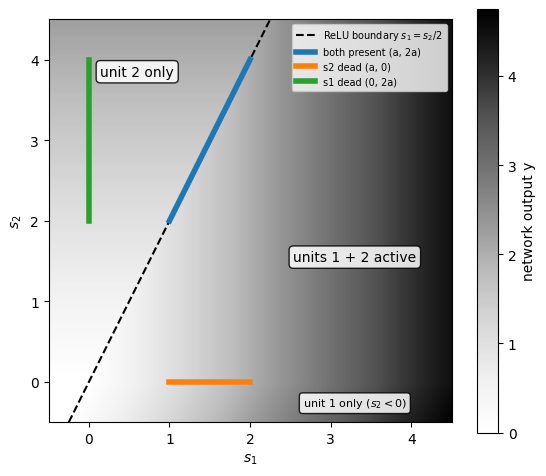

In [6]:
g = torch.linspace(-0.5, 4.5, 301)
S1, S2 = torch.meshgrid(g, g, indexing="xy")
with torch.no_grad():
    out_0a = net_0a(torch.stack([S1.ravel(), S2.ravel()], dim=1)).reshape(S1.shape).numpy()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.pcolormesh(S1.numpy(), S2.numpy(), out_0a, cmap="Greys", shading="auto")
fig.colorbar(im, ax=ax, label="network output y")
ax.plot([-0.25, 2.25], [-0.5, 4.5], "k--", lw=1.5, label="ReLU boundary $s_1 = s_2/2$")
a_np = a_pos.numpy()
ax.plot(a_np, 2 * a_np, color="tab:blue", lw=4, label="both present (a, 2a)")
ax.plot(a_np, 0 * a_np, color="tab:orange", lw=4, label="s2 dead (a, 0)")
ax.plot(0 * a_np, 2 * a_np, color="tab:green", lw=4, label="s1 dead (0, 2a)")
box = dict(boxstyle="round", fc="white", alpha=0.85)
ax.text(3.3, 1.5, "units 1 + 2 active", ha="center", bbox=box)
ax.text(0.6, 3.8, "unit 2 only", ha="center", bbox=box)
ax.text(3.3, -0.3, "unit 1 only ($s_2 < 0$)", ha="center", fontsize=8, bbox=box)
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-0.5, 4.5)
ax.set_xlabel("$s_1$")
ax.set_ylabel("$s_2$")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=7)
plt.show()

## 0B. Hand-built network with flags, for signed signals (no training)

Now $a \in [-2, 2]$ and the input is $(s_1, s_2, m_1, m_2)$, with $m = 1$ meaning failed. Linear(4, 4) → ReLU → Linear(4, 1), with $M = 10$:
- Units 1−2 compute $\mathrm{ReLU}(s_1) - \mathrm{ReLU}(-s_1) = s_1$, but only when $m_1 = 0$.
- Units 3−4 compute $s_2/2$, but only when $m_1 = 1$.

The flag shifts a unit far into its "off" region, so it acts as a switch. This is the same multiplicative gating that GRU gates perform.

In [7]:
M = 10
net_0b = tiny_net(
    W1=[[1, 0, -M, 0],
        [-1, 0, -M, 0],
        [0, 0.5, M, 0],
        [0, -0.5, M, 0]],
    b1=[0, 0, -M, -M],
    W2=[[1, -1, 1, -1]],
    b2=[0],
)
print("a in [-2, 2], with flags")
max_abs_error_table(net_0b, a_signed, flags=True)

a in [-2, 2], with flags


,max |error|
both present,0.000000e+00
s2 dead,0.000000e+00
s1 dead,4.768372e-07


**Figure 0B.** One panel per condition shows the four hidden-unit activations against $a$. With $m_1 = 0$ (both present, s2 dead) only units 1–2 carry signal; with $m_1 = 1$ (s1 dead) only units 3–4 do.

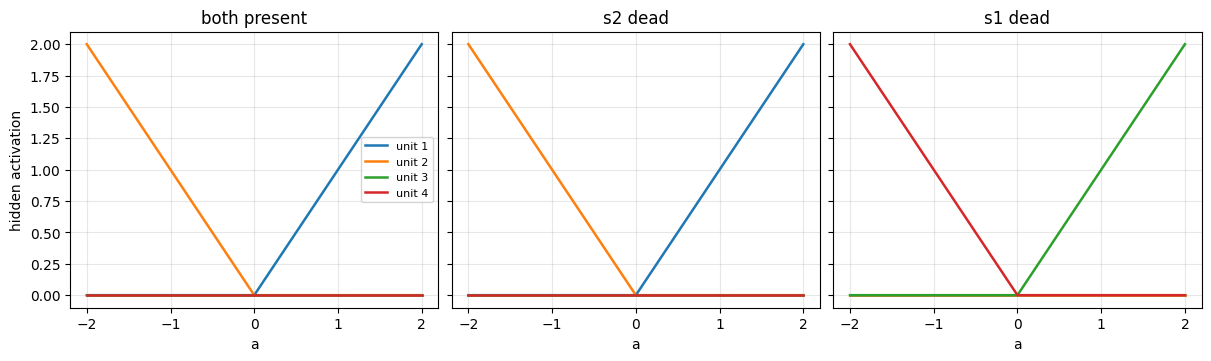

In [8]:
def plot_activations(axes, net, a, title_prefix=""):
    for ax, c in zip(axes, CONDITIONS):
        h = hidden_activations(net, a, c)
        for j in range(h.shape[1]):
            ax.plot(a.numpy(), h[:, j], lw=1.8, label=f"unit {j + 1}")
        ax.set_title(f"{title_prefix}{c}")
        ax.set_xlabel("a")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("hidden activation")
    axes[0].legend(fontsize=8)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True, constrained_layout=True)
plot_activations(axes, net_0b, a_signed)
plt.show()

## 0C. Tiny trained networks (same signed problem with flags as 0B)

$a \sim U[-2, 2]$, with the condition drawn uniformly per sample. Linear(4, w) → ReLU → Linear(w, 1) for $w \in \{2, 4, 8\}$ and seeds 0–4. Adam with lr 1e-2, 4000 steps, a fresh batch of 256 every step, MSE loss, no early stopping. The test set is 5000 fresh samples drawn with a fixed seed. The metric is relative MSE = MSE / Var(y).

In [9]:
def sample_toy(n, gen):
    a = torch.rand(n, generator=gen) * 4 - 2
    cond = torch.randint(0, len(CONDITIONS), (n,), generator=gen)
    x = torch.zeros(n, 4)
    for i, c in enumerate(CONDITIONS):
        sel = cond == i
        x[sel] = toy_inputs(a[sel], c, flags=True)
    return x, a[:, None]


def train_tiny(w, seed, steps=4000, batch=256, lr=1e-2):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(4, w), nn.ReLU(), nn.Linear(w, 1))
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(steps):
        x, y = sample_toy(batch, gen)
        loss = ((net(x) - y) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return net


x_toy_te, y_toy_te = sample_toy(5000, torch.Generator().manual_seed(12345))
tiny_runs, tiny_rows = {}, []
for w in [2, 4, 8]:
    for seed in range(5):
        net = train_tiny(w, seed)
        with torch.no_grad():
            rel = (((net(x_toy_te) - y_toy_te) ** 2).mean() / y_toy_te.var(unbiased=False)).item()
        tiny_runs[(w, seed)] = net
        tiny_rows.append({"width": w, "seed": seed, "rel_mse": rel})
tiny_results = pd.DataFrame(tiny_rows)
tiny_results.pivot(index="width", columns="seed", values="rel_mse").style.format("{:.2e}")

seed,0,1,2,3,4
width,,,,,
2,7.78e-02,1.74e-10,8.91e-09,7.49e-11,5.55e-09
4,5.09e-09,1.93e-07,4.07e-09,1.36e-09,6.11e-09
8,9.17e-05,4.46e-09,2.11e-07,1.91e-07,4.90e-07


**Result.** 14 of the 15 runs are close to exact: relative MSE between 7e-11 and 5e-7, apart from w = 8 seed 0 at 9e-5, which is small but not at the 1e-7 level. **One w = 2 run (seed 0) got stuck at relative MSE 7.8e-2.** In the activation plot below, its unit 1 is dead (never active for any $a$ or condition), so the network is left with one ReLU and cannot form the gated map. The other four w = 2 seeds found a solution, so a width-2 network *can* represent this map. Seed 0's training failed. A stuck run is a training failure, not a limit of fixed weights. It has not been re-seeded or tuned away.

**Best w = 2 run.** Its weights are printed below, and its two hidden activations are plotted per condition in the same layout as Figure 0B, for comparison with the hand-built gating. If a w = 2 run got stuck (relative MSE > 1e-3), the worst one is shown in a second row.

best w=2 run: seed 3, relative MSE 7.49e-11
0.weight:
[[-0.81  -0.379  1.616  1.513]
 [ 0.598  0.319  1.463  1.382]]
0.bias:
[ 0.239 -0.189]
2.weight:
[[-0.638  0.809]]
2.bias:
[0.153]


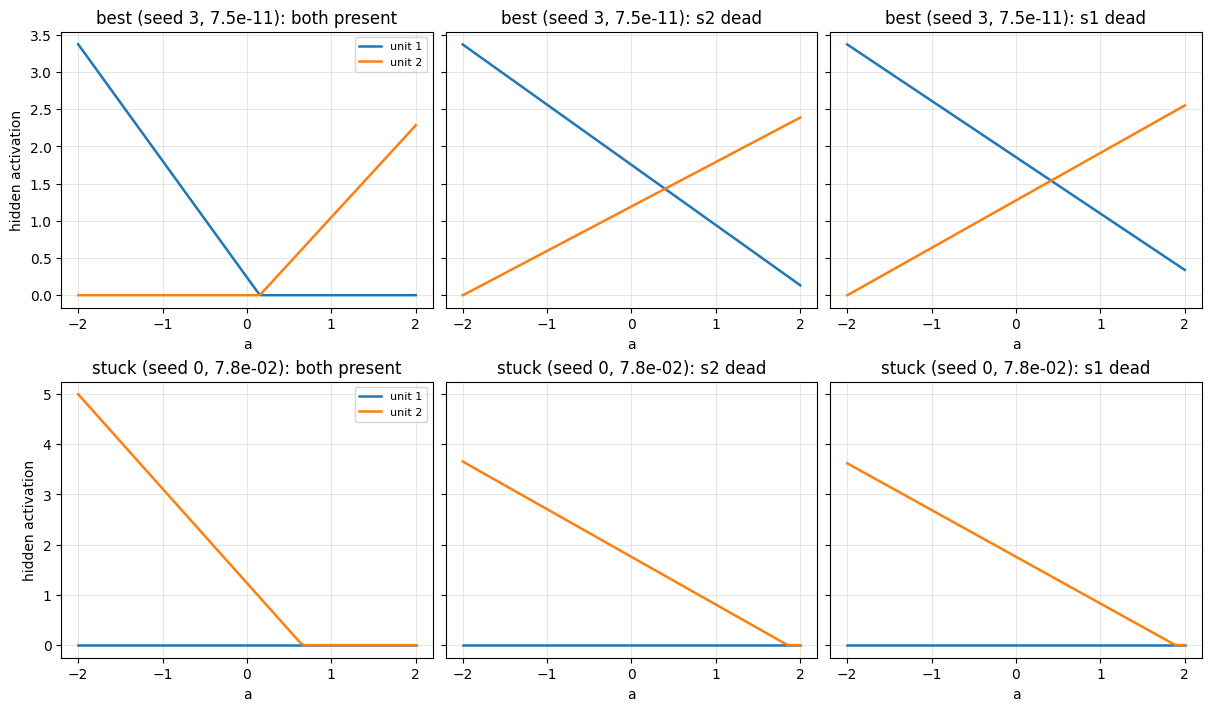

In [10]:
w2_runs = tiny_results[tiny_results.width == 2].sort_values("rel_mse")
best_seed, worst_seed = int(w2_runs.seed.iloc[0]), int(w2_runs.seed.iloc[-1])
best_net = tiny_runs[(2, best_seed)]
print(f"best w=2 run: seed {best_seed}, relative MSE {w2_runs.rel_mse.iloc[0]:.2e}")
for name, p in best_net.named_parameters():
    print(f"{name}:\n{np.round(p.detach().numpy(), 3)}")

stuck = w2_runs.rel_mse.iloc[-1] > 1e-3
rows_plot = [("best", best_seed)] + ([("stuck", worst_seed)] if stuck else [])
fig, axes = plt.subplots(len(rows_plot), 3, figsize=(12, 3.5 * len(rows_plot)), sharey="row",
                         constrained_layout=True, squeeze=False)
for row, (label, seed) in zip(axes, rows_plot):
    rel = float(w2_runs.set_index("seed").rel_mse[seed])
    plot_activations(row, tiny_runs[(2, seed)], a_signed, title_prefix=f"{label} (seed {seed}, {rel:.1e}): ")
plt.show()

## 0D. What Part 0 established

- **A fixed-weight ReLU network can implement a different map per failure pattern.** In 0A the error is 0 in all three conditions for $a \in [1, 2]$, and in 0B for signed $a$ with flags. Figures 0A and 0B show each pattern using a different linear piece or a different set of active units.
- **A linear model cannot.** In the 0A linear comparison, the best single least-squares map has a max error of 0.5 in every condition.
- **A zero that can also be a genuine reading is ambiguous without flags, and flags remove the ambiguity.** In 0A on $a \in [-2, 2]$ the errors reach 2–4. In 0B, with flags, the error is ≤ 5e-7.
- **Training can fail even when a solution exists.** In 0C, w = 2 seed 0 is stuck at 7.8e-2 with a dead unit, while the other w = 2 seeds reach ≤ 9e-9. A single failed run is not evidence that the map cannot be represented.

## Data generation

$z_{t+1} = A z_t + w_t$, $w_t \sim \mathcal N(0, qI)$, $A = \rho\, V B V^\top$; sensors $s_t = C z_t + \varepsilon_t$, outputs $y_t = D z_t$.
Contiguous 70/15/15 split, z-scored with training statistics. Windows of L lags are built inside each split; both models use the same target times.

In [11]:
def make_A(r, rng, rho=0.99):
    V, _ = np.linalg.qr(rng.standard_normal((r, r)))
    angles = [2 * np.pi / 12, 2 * np.pi / 7]
    B = np.zeros((r, r))
    for b in range(r // 2):
        c, s = np.cos(angles[b]), np.sin(angles[b])
        B[2 * b:2 * b + 2, 2 * b:2 * b + 2] = [[c, -s], [s, c]]
    if r % 2 == 1:
        B[-1, -1] = 1.0
    return rho * V @ B @ V.T


def make_windows(x, y):
    # windows t-L+1 .. t inside one split; target y_t at the last lag
    idx = np.arange(L - 1, len(x))
    xw = np.stack([x[t - L + 1:t + 1] for t in idx])
    return torch.tensor(xw, dtype=torch.float32), torch.tensor(y[idx], dtype=torch.float32)


def generate_data(r, seed, T=6000, burn_in=500, q=0.01, sensor_std=0.01):
    rng = np.random.default_rng(seed)
    A = make_A(r, rng)
    C = rng.standard_normal((N_SENSORS, r))
    D = rng.standard_normal((N_OUTPUTS, r))

    z = np.zeros((T, r))
    w = rng.normal(0.0, np.sqrt(q), size=(T, r))
    for t in range(T - 1):
        z[t + 1] = A @ z[t] + w[t]
    z = z[burn_in:]
    s = z @ C.T + rng.normal(0.0, sensor_std, size=(len(z), N_SENSORS))
    y = z @ D.T

    n = len(z)
    n_tr, n_va = int(0.7 * n), int(0.15 * n)
    bounds = {"train": (0, n_tr), "val": (n_tr, n_tr + n_va), "test": (n_tr + n_va, n)}
    s_mu, s_sd = s[:n_tr].mean(0), s[:n_tr].std(0)
    y_mu, y_sd = y[:n_tr].mean(0), y[:n_tr].std(0)
    s, y = (s - s_mu) / s_sd, (y - y_mu) / y_sd

    data = {"C": C, "r": r, "seed": seed}
    for name, (a, b) in bounds.items():
        data[name] = make_windows(s[a:b], y[a:b])
    # fixed corrupted validation set, same procedure as training corruption
    gen = torch.Generator().manual_seed(1000 + seed)
    data["val_mask"] = sample_masks(len(data["val"][0]), gen)
    return data

## Corruption

A failed sensor is zeroed at every lag of the window; 5 flags (1 = failed) are appended to each time step, giving 10 features per step.
Training masks draw k uniformly from {0,…,4}, then k sensors uniformly at random, independently per sample.

In [12]:
def sample_masks(n, gen):
    k = torch.randint(0, N_SENSORS, (n,), generator=gen)              # k in {0,...,4}
    rank = torch.argsort(torch.rand(n, N_SENSORS, generator=gen), dim=1)
    return rank < k[:, None]                                          # (n, 5) bool, True = failed


def pattern_mask(n, failed):
    m = torch.zeros(n, N_SENSORS, dtype=torch.bool)
    m[:, list(failed)] = True
    return m


def corrupt(xw, mask):
    # xw: (n, L, 5) z-scored sensor windows; mask: (n, 5) bool
    values = xw * (~mask)[:, None, :]
    flags = mask.float()[:, None, :].expand(-1, xw.shape[1], -1)
    return torch.cat([values, flags], dim=-1)                         # (n, L, 10)

## Models

In [13]:
class StaticMLP(nn.Module):
    # uses only the 10 features at time t (the last lag of the window)
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(10, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, N_OUTPUTS))

    def forward(self, x):
        return self.net(x[:, -1, :])


class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(10, 32, num_layers=1, batch_first=True)
        self.head = nn.Sequential(nn.Linear(32, 64), nn.ReLU(), nn.Linear(64, N_OUTPUTS))

    def forward(self, x):
        _, h = self.gru(x)
        return self.head(h[-1])


MODELS = {"MLP": StaticMLP, "GRU": GRUModel}

## Training

In [14]:
def train_model(model_name, data, seed, lr=1e-3, batch_size=128, max_epochs=300, eval_every=5, patience=6):
    torch.manual_seed(seed)
    model = MODELS[model_name]()
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    x_tr, y_tr = data["train"]
    x_va = corrupt(data["val"][0], data["val_mask"])
    y_va = data["val"][1]

    best_loss, best_state, bad, epochs_run = np.inf, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(x_tr), generator=gen)
        for i in range(0, len(perm), batch_size):
            b = perm[i:i + batch_size]
            xb = corrupt(x_tr[b], sample_masks(len(b), gen))
            loss = loss_fn(model(xb), y_tr[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
        epochs_run = epoch
        if epoch % eval_every == 0:
            model.eval()
            with torch.no_grad():
                val_loss = loss_fn(model(x_va), y_va).item()
            if val_loss < best_loss:
                best_loss, bad = val_loss, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience:
                    break
    model.load_state_dict(best_state)
    model.eval()
    return model, {"best_val_mse": best_loss, "epochs": epochs_run}

## Evaluation

Relative MSE (z-scored units) = MSE over the 10 outputs / mean variance of the test outputs, averaged over all C(5, k) failure patterns of size k, each applied to the whole test set.
The static identifiability check is the fraction of size-k patterns whose remaining rows $C_S$ have rank r.

In [15]:
def relative_mse(pred, y):
    return (((pred - y) ** 2).mean() / y.var(dim=0, unbiased=False).mean()).item()


def evaluate(model, data):
    x_te, y_te = data["test"]
    out = {}
    with torch.no_grad():
        for k in K_VALUES:
            errs = [relative_mse(model(corrupt(x_te, pattern_mask(len(x_te), S))), y_te)
                    for S in itertools.combinations(range(N_SENSORS), k)]
            out[k] = float(np.mean(errs))
    return out


def identifiability(C, r):
    out = {}
    for k in K_VALUES:
        full = [np.linalg.matrix_rank(np.delete(C, list(S), axis=0)) == r
                for S in itertools.combinations(range(N_SENSORS), k)]
        out[k] = float(np.mean(full))
    return out

## Run all (model, r, seed) combinations

In [16]:
rows, ident_rows, trained = [], [], {}
t_start = time.time()
for r in R_VALUES:
    for seed in SEEDS:
        data = generate_data(r, seed)
        for k, frac in identifiability(data["C"], r).items():
            ident_rows.append({"r": r, "seed": seed, "k": k, "full_rank_fraction": frac})
        for model_name in MODELS:
            t0 = time.time()
            model, info = train_model(model_name, data, seed)
            trained[(model_name, r, seed)] = model
            for k, err in evaluate(model, data).items():
                rows.append({"model": model_name, "r": r, "seed": seed, "k": k, "rel_mse": err, **info})
            print(f"{model_name:3s} r={r} seed={seed}: epochs={info['epochs']:3d} "
                  f"val={info['best_val_mse']:.4f} ({time.time() - t0:.1f}s)")
print(f"total {time.time() - t_start:.0f}s")

results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
ident = pd.DataFrame(ident_rows)
summary = results.groupby(["model", "r", "k"])["rel_mse"].agg(["mean", "std"]).reset_index()

MLP r=1 seed=0: epochs=190 val=0.0020 (2.9s)


GRU r=1 seed=0: epochs=190 val=0.0017 (14.1s)


MLP r=1 seed=1: epochs=135 val=0.0005 (1.9s)


GRU r=1 seed=1: epochs=135 val=0.0006 (10.6s)


MLP r=1 seed=2: epochs=205 val=0.0004 (3.0s)


...

GRU r=5 seed=0: epochs=245 val=0.0560 (18.4s)


MLP r=5 seed=1: epochs=100 val=0.2677 (1.4s)


GRU r=5 seed=1: epochs=260 val=0.0545 (19.7s)


MLP r=5 seed=2: epochs=115 val=0.5488 (1.7s)


GRU r=5 seed=2: epochs=220 val=0.0714 (19.1s)
total 266s


## Figure 1: relative MSE heatmaps

Each cell is the seed-averaged relative MSE for hidden dimension r (rows) and number of failed sensors k (columns), on a shared log colour scale.
The black step line is the static boundary 5 − k = r: cells to its left have at least r surviving sensors (one snapshot suffices), cells to its right do not.
Compare how sharply each model's error changes across that line.

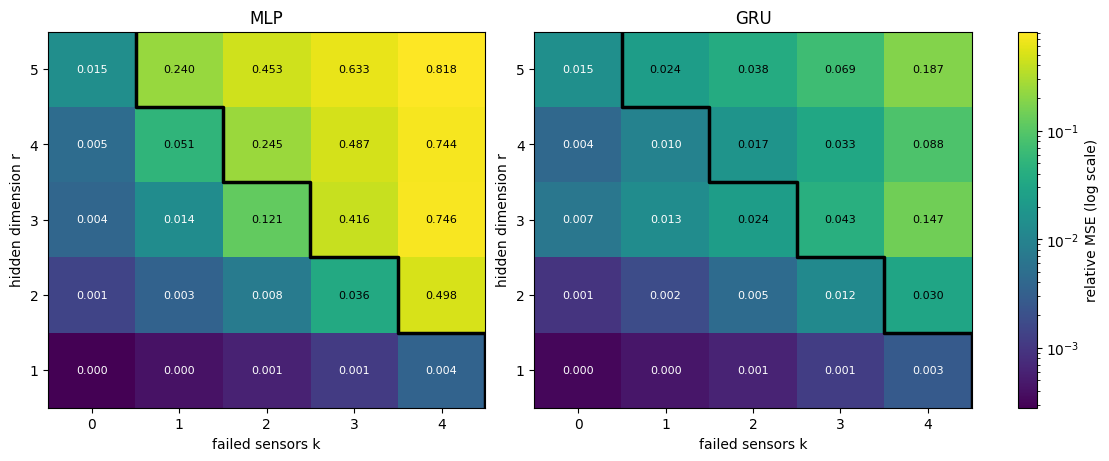

In [17]:
grids = {m: summary[summary.model == m].pivot(index="r", columns="k", values="mean").loc[R_VALUES, K_VALUES].values
         for m in MODELS}
vmin = min(g.min() for g in grids.values())
vmax = max(g.max() for g in grids.values())
norm = LogNorm(vmin=vmin, vmax=vmax)

# step line: row r is "enough" for k <= 5 - r, so the boundary sits at x = 5 - r + 0.5
bx, by = [], []
for i, r in enumerate(R_VALUES):
    xb = N_SENSORS - r + 0.5
    bx += [xb, xb]
    by += [i - 0.5, i + 0.5]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, (m, g) in zip(axes, grids.items()):
    im = ax.imshow(g, norm=norm, cmap="viridis", origin="lower", aspect="auto")
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            v = g[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if norm(v) < 0.5 else "black")
    ax.plot(bx, by, color="black", lw=2.5, drawstyle="default")
    ax.set_xticks(range(len(K_VALUES)), K_VALUES)
    ax.set_yticks(range(len(R_VALUES)), R_VALUES)
    ax.set_xlabel("failed sensors k")
    ax.set_ylabel("hidden dimension r")
    ax.set_title(m)
fig.colorbar(im, ax=axes, label="relative MSE (log scale)")
plt.show()

## Figure 2: error vs number of failed sensors

One colour per hidden dimension r; solid lines are the MLP and dashed lines the GRU, with shaded bands showing ±1 std over seeds.
Look at where each MLP curve rises (expected at k > 5 − r) and whether the matching GRU curve stays flat there.

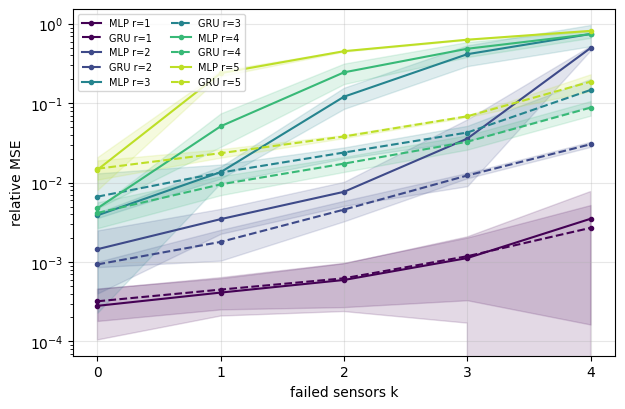

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(R_VALUES)))
for r, c in zip(R_VALUES, colors):
    for m, ls in [("MLP", "-"), ("GRU", "--")]:
        d = summary[(summary.model == m) & (summary.r == r)].sort_values("k")
        ax.plot(d.k, d["mean"], ls, color=c, marker="o", ms=3, label=f"{m} r={r}")
        ax.fill_between(d.k, d["mean"] - d["std"], d["mean"] + d["std"], color=c, alpha=0.15)
ax.set_yscale("log")
ax.set_xticks(K_VALUES)
ax.set_xlabel("failed sensors k")
ax.set_ylabel("relative MSE")
ax.legend(ncol=2, fontsize=7)
ax.grid(alpha=0.3)
plt.show()

## Figure 3: example time series (r = 3, sensors {1, 2, 3} failed, seed 0)

With k = 3 only sensors 0 and 4 remain, fewer than r = 3, so a single snapshot cannot determine the state.
Compare how closely the MLP and the GRU follow the true output 0 (z-scored) over the first 200 test steps.

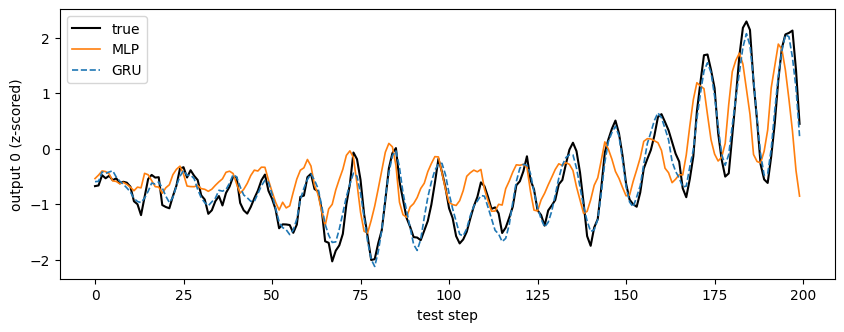

In [19]:
data = generate_data(3, 0)
x_te, y_te = data["test"]
x_in = corrupt(x_te, pattern_mask(len(x_te), [1, 2, 3]))
n_show = 200
with torch.no_grad():
    preds = {m: trained[(m, 3, 0)](x_in)[:n_show, 0].numpy() for m in MODELS}

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(y_te[:n_show, 0].numpy(), color="black", lw=1.5, label="true")
ax.plot(preds["MLP"], color="tab:orange", lw=1.2, label="MLP")
ax.plot(preds["GRU"], color="tab:blue", lw=1.2, ls="--", label="GRU")
ax.set_xlabel("test step")
ax.set_ylabel("output 0 (z-scored)")
ax.legend()
plt.show()

## Static identifiability

The fraction of size-k failure patterns for which the remaining rows $C_S$ have rank r (mean over seeds). No network involved.

In [20]:
ident_table = ident.groupby(["r", "k"])["full_rank_fraction"].mean().unstack("k")
ident_table

k,0,1,2,3,4
r,,,,,
1,1.0,1.0,1.0,1.0,1.0
2,1.0,1.0,1.0,1.0,0.0
3,1.0,1.0,1.0,0.0,0.0
4,1.0,1.0,0.0,0.0,0.0
5,1.0,0.0,0.0,0.0,0.0


## What this shows

*(placeholder)*